# 05 · Dataset unificado, split por toalla y recortes

Este notebook documenta cómo se construyen los datos de entrenamiento de la versión 2 del detector
(`scripts/04_build_dataset.py`).

**Ideas clave**
1. Se unifican las dos rondas de anotación (abril y junio 2025) y las toallas OK.
2. El split train / val / test se hace **por toalla**, antes de recortar, para que ninguna toalla aporte información a dos splits.
3. Los defectos son diminutos respecto a la foto (mediana ~100 px en fotos de 3580 px). Por eso se trabaja con **recortes a resolución nativa** en lugar de reducir la foto completa a 640 px.
4. En producción llega **una foto por toalla**: esa foto se recorta igual que en entrenamiento, se evalúa cada recorte y se combinan los resultados. El flujo de entrenamiento y el de producción son el mismo.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from galia import config as C
from galia.data import load_manifest, load_image, load_boxes
from galia.tiling import tile_grid
from galia.roi import towel_mask
from galia import viz
viz.setup()
df = load_manifest(include_unreadable=True)
print(f"{len(df)} fotos de toallas | ilegibles: {(~df.readable).sum()}")

1538 fotos de toallas | ilegibles: 1


## 1. Fuentes de datos

| Fuente | Captura | Resolución | Contenido | Uso |
|---|---|---|---|---|
| **A** `01_annotated_data` | abril 2025 | 5120×5120 | piezas NO OK con cajas (14 clases) | YOLO, clasificador, evaluación |
| **B** `02_New_Annotated/imagenes no ok` | junio 2025 | 3580×2150 | piezas NO OK con cajas (19 clases) | YOLO, clasificador, evaluación |
| **C** `02_New_Annotated/imagenes ok` | junio 2025 | 3580×2150 | piezas OK, solo `Etiqueta` anotada | YOLO (negativos), todos |
| **D** `new_by_category/PIEZAS OK` | abril 2025 | 5120×5120 | piezas OK sin cajas | clasificador, PatchCore, evaluación |

El set de 2024 (`data/raw`, 2448×2048, fondo blanco sobreexpuesto) usa un montaje distinto y **no se usa**.
Una foto de la fuente D tiene un error de CRC en disco (archivo corrupto) y se excluye.

In [2]:
tab = df[df.readable].groupby(["split", "source", "label"]).size().unstack(["source", "label"]).fillna(0).astype(int)
tab["Total"] = tab.sum(1)
tab.loc["Total"] = tab.sum()
tab

C:\Users\Marcony1\AppData\Local\Temp\ipykernel_48568\3772744216.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  tab["Total"] = tab.sum(1)
C:\Users\Marcony1\AppData\Local\Temp\ipykernel_48568\3772744216.py:2: Pandas4Warning: Setting a new column on a DataFrame with a MultiIndex using a key that is not a full-length tuple is deprecated and will raise in a future version. Use a full-length tuple key instead.
  tab["Total"] = tab.sum(1)


source,A,B,C,D,Total
label,NG,NG,OK,OK,
split,,,,,
test,34,40,37,120,231
train,158,183,174,561,1076
val,34,39,38,119,230
Total,226,262,249,800,1537


## 2. Escala: dos cámaras, una sola escala de píxel
La cámara de abril ve la toalla ~1.6× más grande que la de junio (la etiqueta mide ~170 px contra ~100 px).
Las fotos de abril se reescalan ×0.62 para que **todos los modelos vean los defectos al tamaño de la cámara de producción** (junio).

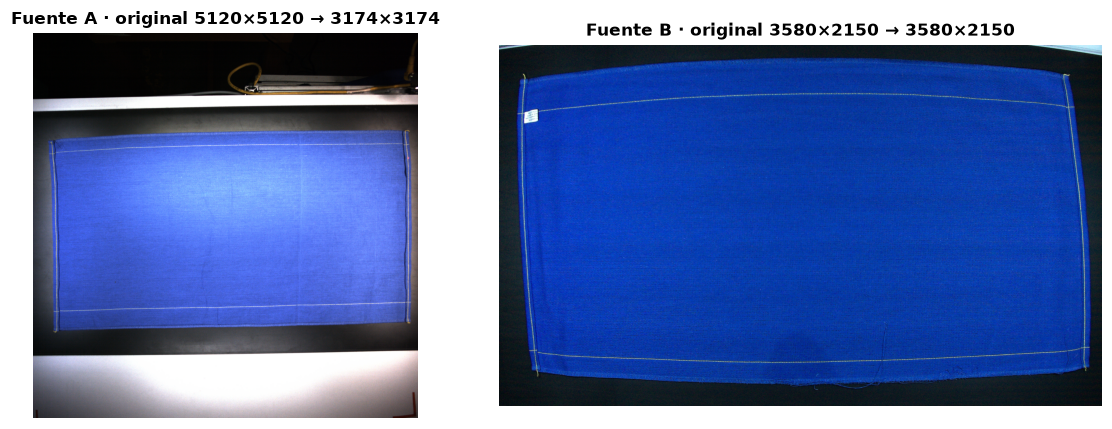

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, src in zip(axes, ["A", "B"]):
    r = df[(df.source == src)].iloc[3]
    img, s = load_image(r.path, r.source)
    ax.imshow(img); ax.set_axis_off()
    ax.set_title(f"Fuente {src} · original {r.width}×{r.height} → {img.shape[1]}×{img.shape[0]}")
plt.tight_layout()

## 3. Taxonomía unificada
Las dos rondas usaron nombres distintos (y algunos con errores de dedo). Se agrupan en **6 grupos de defecto + `Etiqueta`**.
`Etiqueta` no es un defecto: es la clase de control que mide la capacidad de detección del modelo. Se ignora al decidir OK / NO OK.

In [4]:
from galia.config import _RAW_TO_GROUP
mapping = pd.DataFrame(sorted(_RAW_TO_GROUP.items(), key=lambda kv: (C.CLASSES.index(kv[1]), kv[0])),
                       columns=["nombre original (normalizado)", "grupo"])
mapping.groupby("grupo", sort=False)["nombre original (normalizado)"].apply(", ".join).to_frame()

,nombre original (normalizado)
grupo,
Etiqueta,etiqueta
Mancha,"macha aceite, mancha, mancha de aceite, mancha..."
Hilo,"hilo, hilo aglomerado, hilo atrapado, hilo sue..."
Costura,"falla over, falla recta, falla ro, over, punta..."
Tejido,"falla en tejido, perforada, perforadas, tejido"
Tenido,"diferencia en tenido, tenido"
Empalme,"empalme, empalmes"


In [5]:
rows = []
for r in df[df.has_boxes].itertuples():
    b = load_boxes(r.label_path, r.width, r.height) * np.array([1, *[C.SOURCE_SCALE[r.source]] * 4])
    for c, x1, y1, x2, y2 in b:
        rows.append(dict(source=r.source, split=r.split, cls=C.CLASSES[int(c)], w=x2 - x1, h=y2 - y1))
boxes = pd.DataFrame(rows)
boxes["lado_mayor"] = boxes[["w", "h"]].max(1)
boxes["lado_menor"] = boxes[["w", "h"]].min(1)
counts = boxes.pivot_table(index="cls", columns="split", values="w", aggfunc="count").reindex(C.CLASSES).fillna(0).astype(int)
counts

C:\Users\Marcony1\AppData\Local\Temp\ipykernel_48568\3351279507.py:7: Pandas4Warning: Starting with pandas version 4.0 all arguments of max will be keyword-only.
  boxes["lado_mayor"] = boxes[["w", "h"]].max(1)
C:\Users\Marcony1\AppData\Local\Temp\ipykernel_48568\3351279507.py:8: Pandas4Warning: Starting with pandas version 4.0 all arguments of min will be keyword-only.
  boxes["lado_menor"] = boxes[["w", "h"]].min(1)


split,test,train,val
cls,,,
Etiqueta,86,441,95
Mancha,82,344,96
Hilo,28,168,22
Costura,41,186,34
Tejido,10,71,9
Tenido,24,90,21
Empalme,5,14,6


C:\Users\Marcony1\AppData\Local\Temp\ipykernel_48568\2620310480.py:12: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot(data, vert=False, tick_labels=order, showfliers=False, medianprops=dict(color=viz.PALETTE[1]))


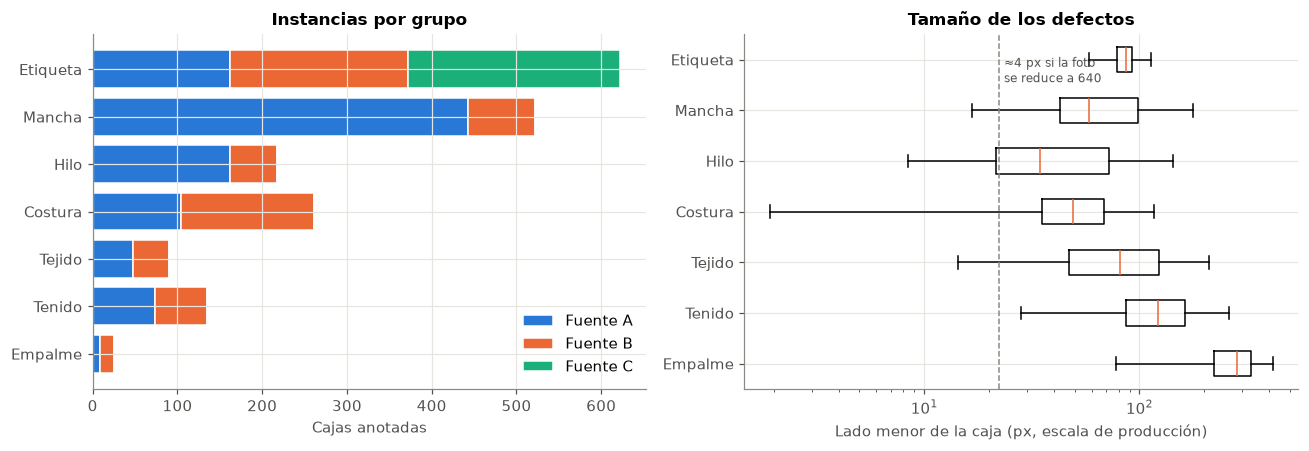

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
order = C.CLASSES
cnt = boxes.groupby(["cls", "source"]).size().unstack().reindex(order).fillna(0)
left = np.zeros(len(order))
for i, src in enumerate(["A", "B", "C"]):
    if src in cnt:
        axes[0].barh(order, cnt[src], left=left, color=viz.PALETTE[i], label=f"Fuente {src}", edgecolor="white", linewidth=1)
        left += cnt[src].to_numpy()
axes[0].invert_yaxis(); axes[0].set_xlabel("Cajas anotadas"); axes[0].legend(loc="lower right")
axes[0].set_title("Instancias por grupo")
data = [boxes.loc[boxes.cls == c, "lado_menor"].to_numpy() for c in order]
axes[1].boxplot(data, vert=False, tick_labels=order, showfliers=False, medianprops=dict(color=viz.PALETTE[1]))
axes[1].set_xscale("log"); axes[1].invert_yaxis()
axes[1].axvline(3580 / 640 * 4, color="#8a8984", ls="--", lw=1)
axes[1].text(3580 / 640 * 4 * 1.05, 1.45, "≈4 px si la foto\nse reduce a 640", fontsize=8, color="#52514e")
axes[1].set_xlabel("Lado menor de la caja (px, escala de producción)")
axes[1].set_title("Tamaño de los defectos")
plt.tight_layout()

La línea punteada marca el tamaño por debajo del cual un defecto queda en ≤4 píxeles si la foto completa se reduce a 640 px,
como hacía el modelo YOLO original. **La mayoría de los hilos, rafias, manchas de óxido y fallas de costura quedan por debajo**,
lo que explica el bajo recall original. Con recortes de 1024 px a resolución nativa, el modelo ve cada defecto con todos sus píxeles.

## 4. Ejemplos anotados

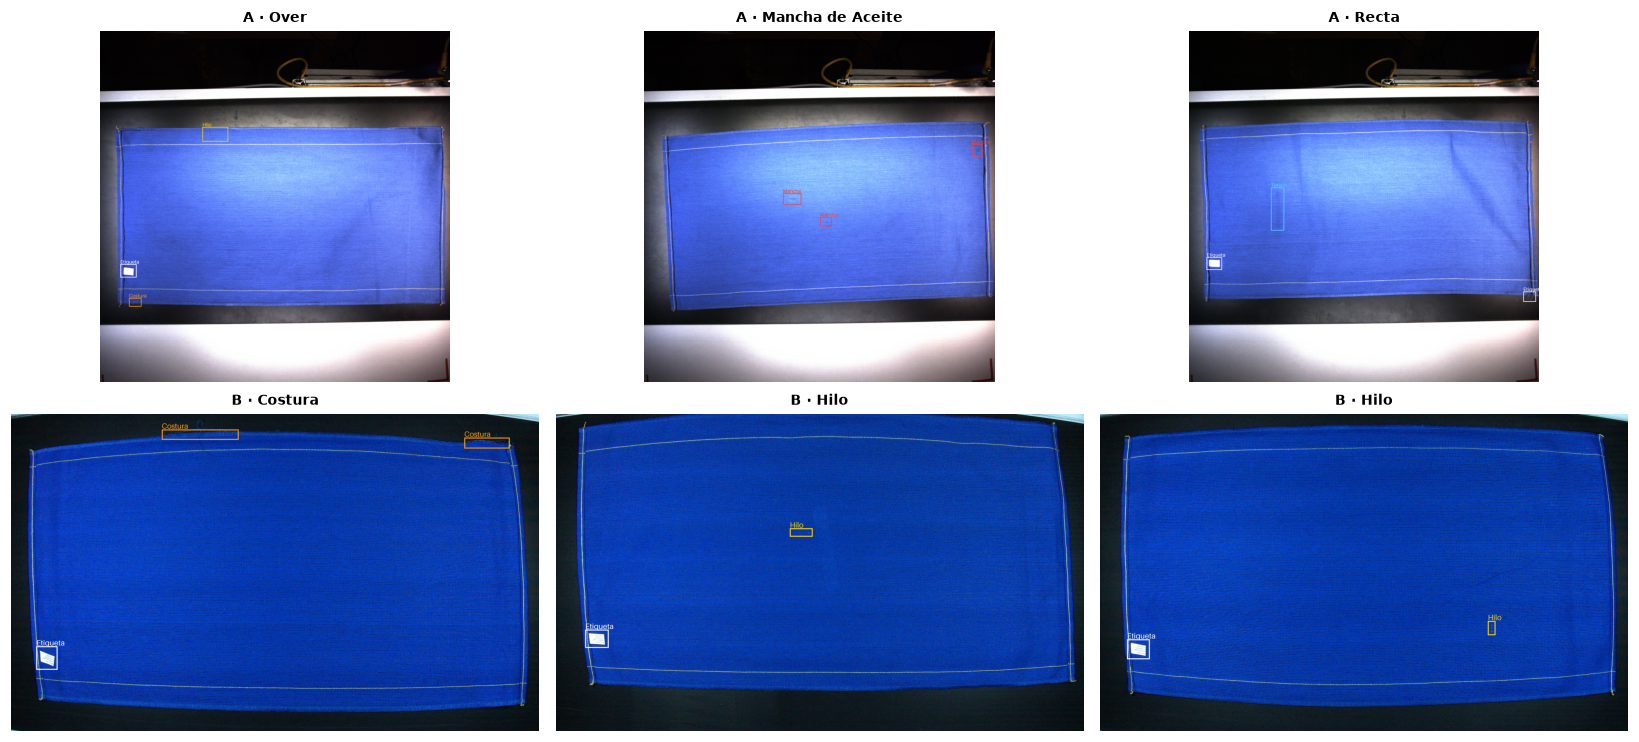

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
ex = pd.concat([df[(df.source == "A") & (df.n_defect_boxes > 0)].sample(3, random_state=1),
                df[(df.source == "B") & (df.n_defect_boxes > 0)].sample(3, random_state=1)])
for ax, r in zip(axes.flat, ex.itertuples()):
    img, s = load_image(r.path, r.source)
    b = load_boxes(r.label_path, r.width, r.height); b[:, 1:] *= s
    ax.imshow(viz.draw_boxes(img, b)); ax.set_axis_off()
    ax.set_title(f"{r.source} · {r.category}", fontsize=9)
plt.tight_layout()

## 5. Recortes y región de la toalla
- **YOLO**: recortes de 1024 px con 25 % de traslape. Una caja se asigna al recorte si se ve al menos el 35 % de ella, o si su parte visible es grande (defectos largos como el teñido cruzan varios recortes).
- **Clasificador**: recortes de 512 px (defecto / limpio).
- **PatchCore**: recortes de 512 px de toallas OK reducidos a 256 px.

La **máscara de la toalla** (por saturación de color) descarta el fondo y las partes de la máquina, que de otro modo generarían falsas alarmas.

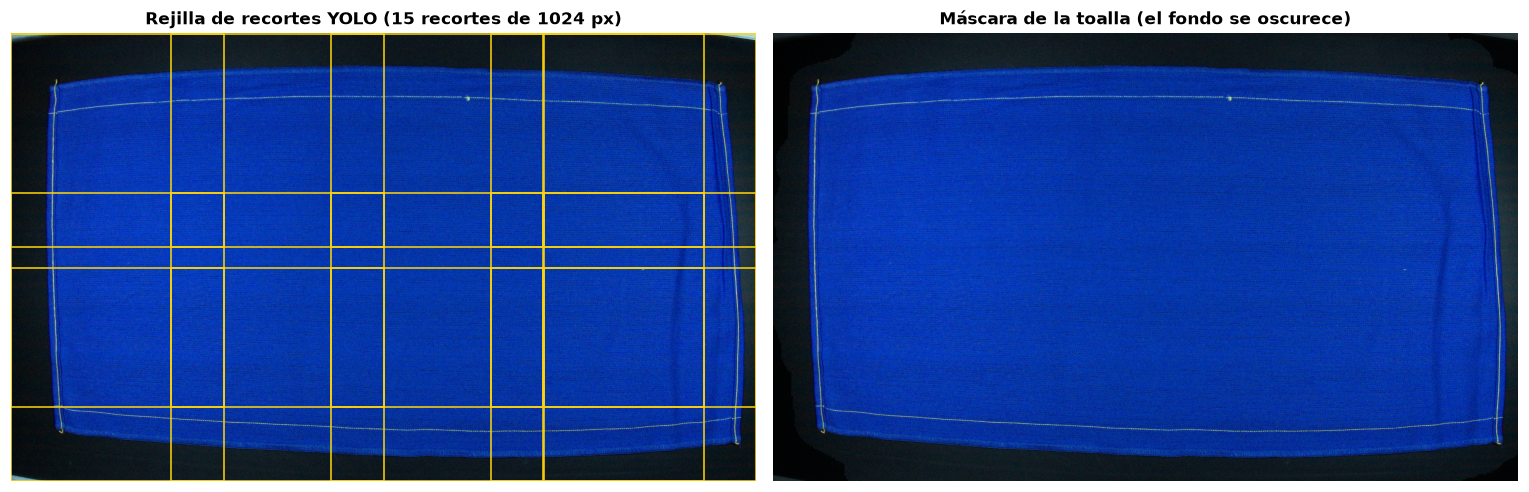

In [8]:
r = df[(df.source == "B") & (df.n_defect_boxes > 0)].iloc[0]
img, s = load_image(r.path, r.source)
mask = towel_mask(img)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
axes[0].imshow(img)
for (x1, y1, x2, y2) in tile_grid(img.shape[1], img.shape[0], C.YOLO_TILE, C.YOLO_OVERLAP):
    axes[0].add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec="#ffd60a", lw=1))
axes[0].set_title(f"Rejilla de recortes YOLO ({len(tile_grid(img.shape[1], img.shape[0], C.YOLO_TILE, C.YOLO_OVERLAP))} recortes de 1024 px)")
axes[0].set_axis_off()
shown = img.copy(); shown[~mask] = (shown[~mask] * 0.25).astype(np.uint8)
axes[1].imshow(shown); axes[1].set_title("Máscara de la toalla (el fondo se oscurece)"); axes[1].set_axis_off()
plt.tight_layout()

In [9]:
def count(p):
    return sum(1 for _ in Path(p).glob("*"))
tiles = pd.DataFrame({
    "YOLO train": [count(C.YOLO_TILES_DIR / "train/images"), sum(1 for f in (C.YOLO_TILES_DIR / "train/labels").glob("*.txt") if f.stat().st_size == 0)],
    "YOLO val": [count(C.YOLO_TILES_DIR / "val/images"), sum(1 for f in (C.YOLO_TILES_DIR / "val/labels").glob("*.txt") if f.stat().st_size == 0)],
    "Clasif. train": [count(C.CLS_TILES_DIR / "train/defect") + count(C.CLS_TILES_DIR / "train/clean"), count(C.CLS_TILES_DIR / "train/clean")],
    "Clasif. val": [count(C.CLS_TILES_DIR / "val/defect") + count(C.CLS_TILES_DIR / "val/clean"), count(C.CLS_TILES_DIR / "val/clean")],
    "PatchCore train": [count(C.PATCHCORE_TILES_DIR / "train/good"), count(C.PATCHCORE_TILES_DIR / "train/good")],
}, index=["recortes", "sin defecto / fondo"]).T
tiles

,recortes,sin defecto / fondo
YOLO train,3344,1184
YOLO val,723,277
Clasif. train,13165,10860
Clasif. val,2695,2220
PatchCore train,2205,2205
